# Module 9: Wednesday Demo
## CS 5045: Computation for the Data Sciences

**This week's operations:** Aggregate and Communicate

We will walk through a complete EDA pipeline on air quality monitoring data from six US cities.
Run each cell in order. Stop at the **Pause and ask** prompts to discuss with the class.

| Operation | Tool | Purpose |
|-----------|------|---------|
| Represent | `pd.read_csv()` | Load data into memory |
| Aggregate | `.describe()`, `.groupby()`, `.agg()` | Summarize |
| Filter | `df[condition]` | Narrow to a subset |
| Transform | `.apply()` | Add a derived column |
| Communicate | `matplotlib` | Make it visible to a human |

---
## CRISP-DM: Where We Are

This module is the first time we name the framework you have been following all semester.

| Phase | What You Do | Where We Are |
|-------|-------------|--------------|
| Business Understanding | Define the question and success criteria | Done in every module brief |
| **Data Understanding** | **Explore and describe the data (EDA)** | **Here, right now** |
| Data Preparation | Clean, filter, and reshape for modeling | Modules 8 and beyond |
| Modeling | Apply statistical or ML techniques | Later in the program |
| Evaluation | Assess results against original goals | Later in the program |
| Deployment | Deliver output to stakeholders | Final project |

Every cell we run today is CRISP-DM Data Understanding. That is all EDA is.

In [1]:
# Represent: load the dataset and confirm it looks right
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv('data.csv')

print(f'Shape: {df.shape}   (rows, columns)')
print(f'\nColumn types:')
print(df.dtypes)
print(f'\nFirst five rows:')
df.head()

Shape: (300, 6)   (rows, columns)

Column types:
city            str
date            str
pm25        float64
ozone       float64
temp_c      float64
humidity      int64
dtype: object

First five rows:


,city,date,pm25,ozone,temp_c,humidity
0,Atlanta,2023-01-04,13.1,0.051,6.3,54
1,Atlanta,2023-01-13,14.1,0.046,2.9,50
2,Atlanta,2023-01-14,18.1,0.043,6.9,54
3,Atlanta,2023-01-16,9.7,0.047,6.7,62
4,Atlanta,2023-01-17,12.1,0.037,5.2,56


---
## Aggregate Step 1: `.describe()`: Eight Summaries at Once

Before anything else, get your bearings. `.describe()` returns count, mean, std, min, quartiles, and max for every numeric column.

> **Pause and ask:** What stands out? Is anything in the range or mean surprising?

In [2]:
# Aggregate: eight statistics for every numeric column
numeric_cols = ['pm25', 'ozone', 'temp_c', 'humidity']
df[numeric_cols].describe().round(2)

,pm25,ozone,temp_c,humidity
count,300.00,300.00,300.00,300.0
mean,12.94,0.05,14.84,58.7
std,3.63,0.01,12.16,14.0
min,3.70,0.03,-14.60,19.0
25%,10.80,0.04,5.85,53.0
50%,13.20,0.05,16.05,61.0
75%,15.20,0.06,25.30,68.0
max,23.70,0.08,37.30,89.0


---
## Aggregate Step 2: GroupBy: Split, Apply, Combine

`.describe()` treats the dataset as a single pool. GroupBy splits it into groups first.

**Pattern:** `df.groupby('category_col')['measure_col'].function()`

> **Pause and ask:** Before running, which city do you predict has the highest mean PM2.5?

In [3]:
# Aggregate: mean PM2.5 per city (split-apply-combine)
city_pm25 = df.groupby('city')['pm25'].mean().round(2)
print('Mean PM2.5 by city:')
print(city_pm25)

print()

# .agg() for multiple named statistics in one call
summary = df.groupby('city').agg(
    readings  = ('pm25', 'count'),
    avg_pm25  = ('pm25', 'mean'),
    max_pm25  = ('pm25', 'max'),
    avg_ozone = ('ozone', 'mean'),
).round(2)
print('Multi-statistic summary table:')
summary

Mean PM2.5 by city:
city
Atlanta        13.27
Chicago        13.46
Denver          8.75
Houston        16.54
Los Angeles    14.69
New York       10.94
Name: pm25, dtype: float64

Multi-statistic summary table:


,readings,avg_pm25,max_pm25,avg_ozone
city,,,,
Atlanta,50,13.27,18.6,0.05
Chicago,50,13.46,18.8,0.04
Denver,50,8.75,14.6,0.06
Houston,50,16.54,23.0,0.06
Los Angeles,50,14.69,23.7,0.06
New York,50,10.94,15.8,0.05


---
## Filter + Aggregate: A Core EDA Pattern

You often want to summarize a **subset** of the data, not all of it.

**Question:** On high-pollution days (PM2.5 > 15), which cities also show elevated ozone?

> **Pause and ask:** How many rows do you expect after the filter?

In [4]:
# Step 1: Filter
high_pm = df[df['pm25'] > 15]
print(f'{len(high_pm)} rows (out of {len(df)}) have PM2.5 > 15:')
print(high_pm[['city', 'date', 'pm25', 'ozone']].to_string(index=False))

print()

# Step 2: Aggregate the filtered subset
print('Mean ozone on high-PM2.5 days, by city:')
high_pm.groupby('city')['ozone'].mean().round(4)

79 rows (out of 300) have PM2.5 > 15:
       city       date  pm25  ozone
    Atlanta 2023-01-14  18.1  0.043
    Atlanta 2023-04-12  16.1  0.048
    Atlanta 2023-04-23  17.3  0.053
    Atlanta 2023-05-06  16.9  0.054
    Atlanta 2023-05-21  15.1  0.067
    Atlanta 2023-05-23  17.5  0.048
    Atlanta 2023-07-13  15.6  0.062
    Atlanta 2023-07-14  18.6  0.062
    Atlanta 2023-08-03  16.4  0.059
    Atlanta 2023-08-24  16.0  0.057
    Atlanta 2023-10-02  15.3  0.047
    Chicago 2023-01-05  17.2  0.036
    Chicago 2023-02-05  15.5  0.044
    Chicago 2023-02-07  18.0  0.032
    Chicago 2023-05-06  15.8  0.048
    Chicago 2023-05-16  15.5  0.057
    Chicago 2023-06-04  16.0  0.043
    Chicago 2023-06-11  16.7  0.063
    Chicago 2023-11-10  15.2  0.035
    Chicago 2023-11-14  17.8  0.035
    Chicago 2023-11-15  16.7  0.032
    Chicago 2023-11-27  18.8  0.036
    Chicago 2023-12-06  16.0  0.041
    Chicago 2023-12-09  15.8  0.041
    Chicago 2023-12-10  17.2  0.040
    Chicago 2023-12-27  18

city
Atlanta        0.0545
Chicago        0.0415
Houston        0.0592
Los Angeles    0.0702
New York       0.0415
Name: ozone, dtype: float64

---
## Transform: Adding a Category Column

Raw numbers are harder to communicate than labels.
`.apply()` runs a function on every row: one value in, one label out.

| PM2.5 | Category |
|-------|----------|
| < 12 ug/m3 | Good |
| 12-20 ug/m3 | Moderate |
| >= 20 ug/m3 | Unhealthy |

In [5]:
# Transform: define the function, apply to every row
def aq_label(v):
    if v < 12:   return 'Good'
    if v < 20:   return 'Moderate'
    return 'Unhealthy'

df['aq_cat'] = df['pm25'].apply(aq_label)

print('New column added:')
print(df[['city', 'date', 'pm25', 'aq_cat']].to_string(index=False))

print()
print('Category counts (Aggregate on the new column):')
print(df['aq_cat'].value_counts())

New column added:
       city       date  pm25    aq_cat
    Atlanta 2023-01-04  13.1  Moderate
    Atlanta 2023-01-13  14.1  Moderate
    Atlanta 2023-01-14  18.1  Moderate
    Atlanta 2023-01-16   9.7      Good
    Atlanta 2023-01-17  12.1  Moderate
    Atlanta 2023-01-23  11.8      Good
    Atlanta 2023-02-10  12.4  Moderate
    Atlanta 2023-02-14  11.2      Good
    Atlanta 2023-02-17  13.6  Moderate
    Atlanta 2023-02-19   9.5      Good
    Atlanta 2023-02-22  15.0  Moderate
    Atlanta 2023-02-27  12.3  Moderate
    Atlanta 2023-03-05  10.4      Good
    Atlanta 2023-03-13   8.2      Good
    Atlanta 2023-03-21  13.3  Moderate
    Atlanta 2023-03-23   9.6      Good
    Atlanta 2023-04-12  16.1  Moderate
    Atlanta 2023-04-21  13.6  Moderate
    Atlanta 2023-04-22  13.7  Moderate
    Atlanta 2023-04-23  17.3  Moderate
    Atlanta 2023-04-25  10.8      Good
    Atlanta 2023-04-30  13.1  Moderate
    Atlanta 2023-05-06  16.9  Moderate
    Atlanta 2023-05-16  10.6      Good
    Atl

---
## Communicate: Bar Chart

**Question answered:** Which city has the highest average PM2.5?

Every element of this chart (title, axis labels, reference line) exists to make the answer legible to a reader who has not seen the data.

> **Pause and ask:** What one sentence would a non-technical reader walk away with?

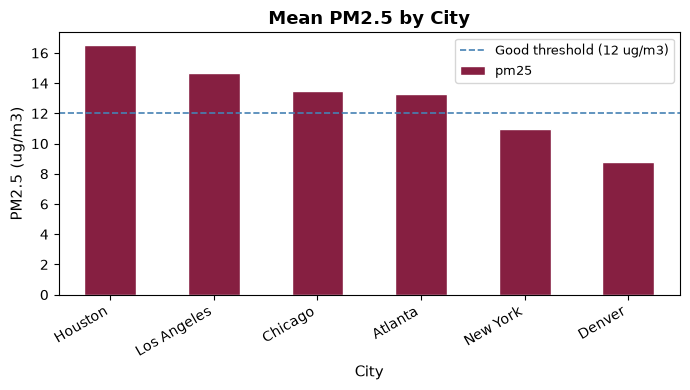

Saved: demo_bar_chart.png


In [6]:
# Communicate: bar chart showing mean PM2.5 by city
fig, ax = plt.subplots(figsize=(7, 4))

city_pm25.sort_values(ascending=False).plot(
    kind='bar', ax=ax, color='#861F41', edgecolor='white'
)
ax.set_title('Mean PM2.5 by City', fontsize=13, fontweight='bold')
ax.set_xlabel('City', fontsize=11)
ax.set_ylabel('PM2.5 (ug/m3)', fontsize=11)
ax.set_xticklabels(ax.get_xticklabels(), rotation=30, ha='right')
ax.axhline(12, color='steelblue', linestyle='--', linewidth=1.2,
           label='Good threshold (12 ug/m3)')
ax.legend(fontsize=9)

plt.tight_layout()
plt.savefig('demo_bar_chart.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: demo_bar_chart.png')

---
## Communicate: Scatter Plot

**Question answered:** Is there a relationship between temperature and PM2.5?

Each point is one reading. The scatter answers a question the bar chart cannot.

> **Pause and ask:** What do you observe? Is this enough to claim that heat *causes* higher PM2.5?

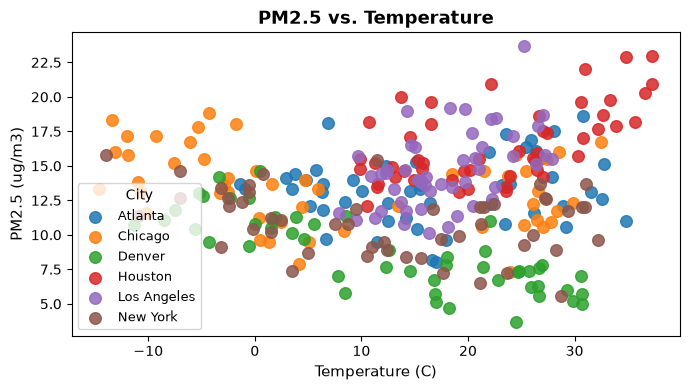

Saved: demo_scatter.png

The pattern above is what hw9.ipynb Section 3 asks you to complete.


In [7]:
# Communicate: scatter plot showing PM2.5 vs. temperature, colored by city
fig, ax = plt.subplots(figsize=(7, 4))

for city, grp in df.groupby('city'):
    ax.scatter(grp['temp_c'], grp['pm25'], label=city, s=70, alpha=0.85)

ax.set_title('PM2.5 vs. Temperature', fontsize=13, fontweight='bold')
ax.set_xlabel('Temperature (C)', fontsize=11)
ax.set_ylabel('PM2.5 (ug/m3)', fontsize=11)
ax.legend(title='City', fontsize=9)

plt.tight_layout()
plt.savefig('demo_scatter.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: demo_scatter.png')

# Assignment connection:
# hw9.ipynb Section 3 asks you to reproduce this pattern on the same dataset:
#   ax.scatter(df['x_col'], df['y_col'], alpha=0.7)
#   ax.set_title('Your title here')
#   ax.set_xlabel('Your x label')
#   ax.set_ylabel('Your y label')
#   plt.savefig('scatter_output.png', dpi=150, bbox_inches='tight')
#   plt.show()
print('\nThe pattern above is what hw9.ipynb Section 3 asks you to complete.')

---
## Terminal Check: Confirm Your PNG Files Are on Disk

A chart rendered in a notebook cell is **not** the same as a file saved to disk.
The cell below lists every PNG in the current folder.

**What you should see:** `demo_bar_chart.png` and `demo_scatter.png`, each with a file size and a recent timestamp.

If either file is missing, scroll back up and re-run the cell that calls `plt.savefig()` for that chart. Never submit an assignment without running this check first.

> **In your system terminal** (outside the notebook), the equivalent command is:
> ```
> ls -la *.png
> ```
> Both approaches confirm the same thing: the file exists on disk with a non-zero size.

In [8]:
# Quick terminal check: list all PNG files in the current working directory.
# If a file is missing here, it did not save -- re-run the savefig cell above.
import os

pngs = sorted(f for f in os.listdir('.') if f.endswith('.png'))

if pngs:
    print(f'Found {len(pngs)} PNG file(s):')
    for fname in pngs:
        size = os.path.getsize(fname)
        print(f'  {fname:40s}  {size:,} bytes')
else:
    print('No PNG files found in this folder.')
    print('Re-run the savefig cells above, then run this cell again.')

Found 2 PNG file(s):
  demo_bar_chart.png                        36,981 bytes
  demo_scatter.png                          139,794 bytes
